In [ ]:
"""A support vector machine (SVM) is a supervised max-margin machine learning algorithm used for classification and regression tasks. It works by finding the optimal hyperplane that maximizes the margin between different classes in the feature space.

Consists of classification error function and distance error function.

Can be Hard Margin / Soft Margin
Hard => No errors allowed
Soft => errors can occur

The Kernal Trick:
Helpful when data is NOT separable

Popular Kernel Functions
Linear Kernel: Used for already linearly separable data; acts as standard dot product. (2D)

Polynomial Kernel: Accounts for feature interactions up to a specified degree, useful for image processing. (3D)

Radial Basis Function (RBF / Gaussian): Maps data into an infinite-dimensional space, excellent for handling complex, overlapping distributions. (> 3D)

SVM Uses Hinge Loss instead of Log-Loss to calc. Error
"""


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("mouse_viral_study.csv")
data

,Med_1_mL,Med_2_mL,Virus Present
0,6.508231,8.582531,0
1,4.126116,3.073459,1
2,6.427870,6.369758,0
3,3.672953,4.905215,1
4,1.580321,2.440562,1
...,...,...,...
395,2.884122,3.271748,1
396,7.290855,9.488672,0
397,7.895325,8.272529,0
398,2.690592,2.674979,1


In [3]:
print(data.head())

   Med_1_mL  Med_2_mL  Virus Present
0  6.508231  8.582531              0
1  4.126116  3.073459              1
2  6.427870  6.369758              0
3  3.672953  4.905215              1
4  1.580321  2.440562              1


In [4]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Med_1_mL       400 non-null    float64
 1   Med_2_mL       400 non-null    float64
 2   Virus Present  400 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 9.5 KB
None


In [5]:
print(data.describe())

         Med_1_mL    Med_2_mL  Virus Present
count  400.000000  400.000000     400.000000
mean     5.447984    5.616750       0.500000
std      2.319059    2.336637       0.500626
min      1.000000    1.000000       0.000000
25%      3.249062    3.431311       0.000000
50%      5.393776    5.638471       0.500000
75%      7.630389    7.782614       1.000000
max     10.000000   10.000000       1.000000


<Axes: xlabel='Med_1_mL', ylabel='Med_2_mL'>

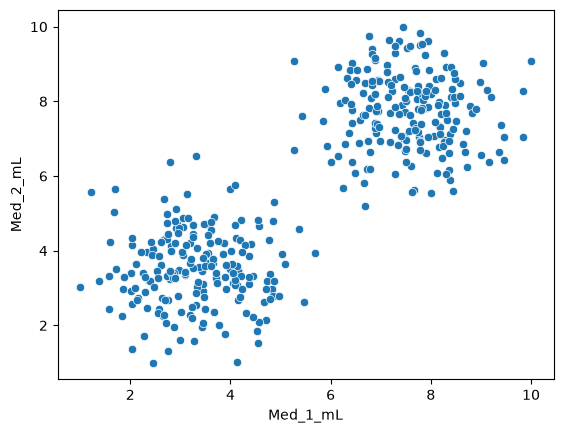

In [6]:
sns.scatterplot(data=data, x="Med_1_mL", y="Med_2_mL")

<Axes: xlabel='Med_1_mL', ylabel='Med_2_mL'>

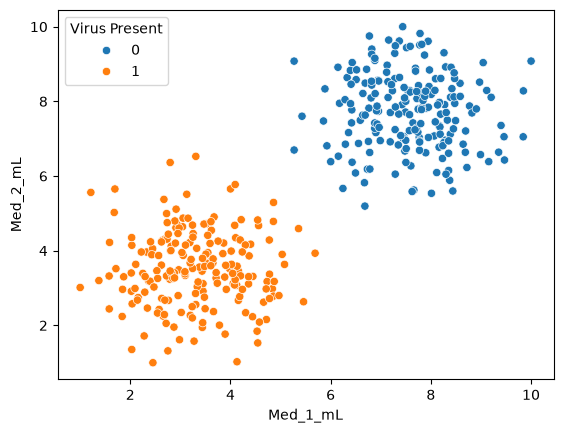

In [7]:
sns.scatterplot(data=data, x="Med_1_mL", y="Med_2_mL", hue="Virus Present")

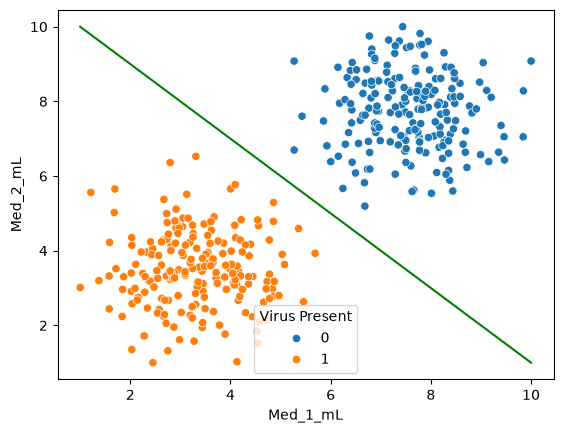

In [ ]:
sns.scatterplot(data=data, x="Med_1_mL", y="Med_2_mL", hue="Virus Present")

# creating hyperplane
x = np.linspace(1, 10, 100)
m = -1
b = 11
y = m*x + b 
plt.plot(x, y, color="green")

# data is well seperated which is linear line

In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
model_svm = SVC(kernel="linear", C=0.1)
# LARGER C = more overfitting, SMALLER means more error
features = data.drop(columns="Virus Present")
target = data["Virus Present"]

Xtrain, Xtest, ytrain, ytest = train_test_split(features, target, random_state=42, test_size=0.2)
model_svm.fit(Xtrain, ytrain)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",0.1
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


c:\Users\moham\Downloads\My Learning\Ai&ML- Route\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


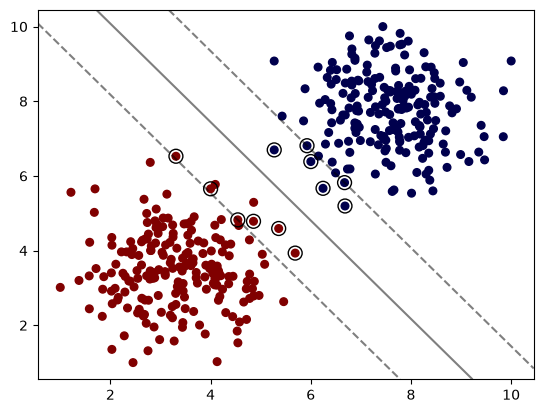

In [ ]:
from svm_margin_plot import plot_svm_boundary
# External file present with function
plot_svm_boundary(model_svm, features, target)

c:\Users\moham\Downloads\My Learning\Ai&ML- Route\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


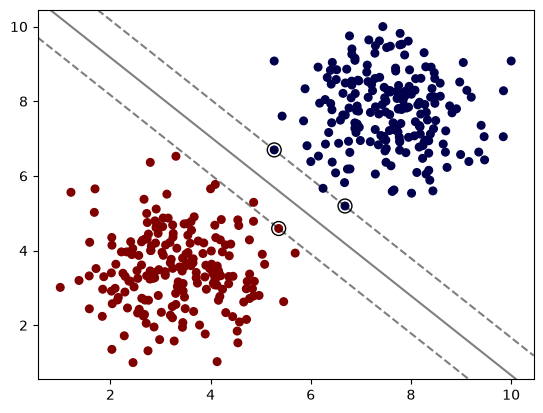

In [ ]:
# Trying diff. kernals and C/ degrees
model_svm = SVC(kernel="linear", C=20)
model_svm.fit(Xtrain, ytrain)
plot_svm_boundary(model_svm, features, target)

c:\Users\moham\Downloads\My Learning\Ai&ML- Route\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


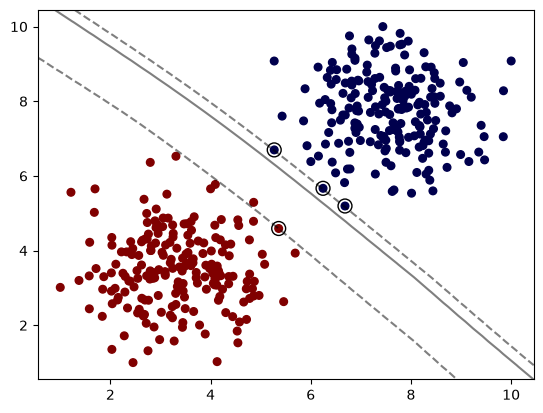

In [26]:
# Trying diff. kernals and C/ degrees
model_svm = SVC(kernel="poly", degree=22)
model_svm.fit(Xtrain, ytrain)
plot_svm_boundary(model_svm, features, target)

c:\Users\moham\Downloads\My Learning\Ai&ML- Route\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


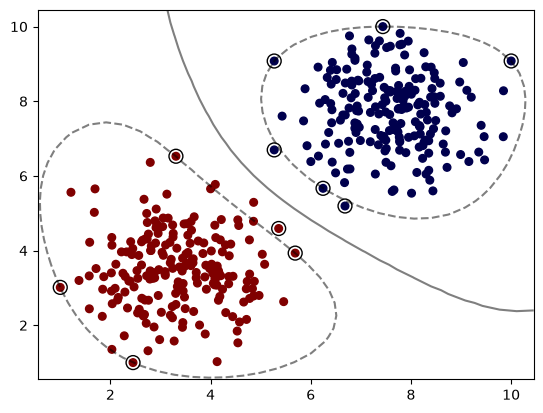

In [22]:
# Trying diff. kernals and C/ degrees
model_svm = SVC(kernel="rbf", C=2, gamma=0.1)
model_svm.fit(Xtrain, ytrain)
plot_svm_boundary(model_svm, features, target)

In [ ]:
"""
GridSearchCV (short for Grid Search Cross-Validation) is a powerful tool provided by scikit-learn used for hyperparameter tuning.

In machine learning, models have two types of parameters:

Model Parameters: Learned automatically during training (like the weights and bias in a linear regression or SVM).

Hyperparameters: Set manually before training begins (like the C and gamma in an SVM, or the max_depth in a decision tree).

GridSearchCV automates the process of finding the optimal combination of these hyperparameters for your model. Instead of manually trying different combinations, you can define a grid of hyperparameter values, and GridSearchCV will exhaustively train and evaluate the model for each combination using cross-validation.
"""

In [30]:
from sklearn.model_selection import GridSearchCV

model = SVC()
parms = {
  "C": [0.01, 0.1, 1, 100],
  "gamma": [0.01, 0.1, 1, 100],
  "kernel": ["linear", "rbf", "poly"],
  "degree" : [1,2 ]
}

In [ ]:
grid = GridSearchCV(model, parms)
grid.fit(features, target)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.01, 0.1, ...], 'degree': [1, 2], 'gamma': [0.01, 0.1, ...], 'kernel': ['linear', 'rbf', ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the ver

In [32]:
print(grid.best_estimator_)
print(grid.best_params_)

SVC(C=0.01, degree=1, gamma=0.01, kernel='linear')
{'C': 0.01, 'degree': 1, 'gamma': 0.01, 'kernel': 'linear'}
